# Time Series Analysis

This notebook accompanies the note [time series analysis](../../notes/time_series/time_series.md). It works through the note's numerical examples:

1. the additive decomposition $y_t=100+0.5t+10\sin(2\pi t/12)+\varepsilon_t$ at $t=3$ and $t=6$;
2. recovering trend and seasonality from simulated data;
3. the monthly sales table with a trailing 3-month moving average and simple exponential smoothing;
4. differencing and seasonal differencing;
5. log transformation for multiplicative behavior and sampling/aliasing;
6. why a centered smoother is not a valid real-time feature (information set).

## 1. The worked decomposition

The deterministic part at $t=3$ is $100+0.5(3)+10\sin(\pi/2)=111.5$ and at $t=6$ it is $100+0.5(6)+10\sin(\pi)=103$. With $\varepsilon_3=-1.2$ the observation at $t=3$ is $110.3$.

t=3: trend= 101.5  seasonal= 10.00  deterministic= 111.50
t=6: trend= 103.0  seasonal=  0.00  deterministic= 103.00
t=3 with eps=-1.2 : 110.3
noise variance (simulated): 3.61  (theory 4)


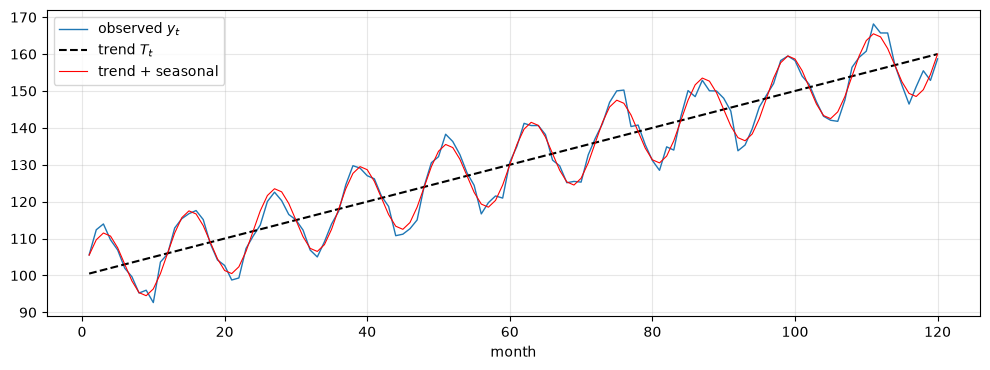

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf

def trend(t):    return 100 + 0.5 * t
def seasonal(t): return 10 * np.sin(2 * np.pi * t / 12)

for t in (3, 6):
    print(f"t={t}: trend={trend(t):6.1f}  seasonal={seasonal(t):6.2f}  deterministic={trend(t)+seasonal(t):7.2f}")
print("t=3 with eps=-1.2 :", round(trend(3) + seasonal(3) - 1.2, 2))

rng = np.random.default_rng(11)
t = np.arange(1, 121)
eps = rng.normal(0, 2, t.size)                 # Var = 4
y = trend(t) + seasonal(t) + eps
print("noise variance (simulated):", round(eps.var(), 2), " (theory 4)")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t, y, lw=1, label="observed $y_t$")
ax.plot(t, trend(t), "k--", label="trend $T_t$")
ax.plot(t, trend(t) + seasonal(t), "r-", lw=0.8, label="trend + seasonal")
ax.legend(); ax.grid(alpha=0.3); ax.set_xlabel("month"); plt.tight_layout(); plt.show()

The printed values match the note ($111.5$, $103$, and $110.3$). The same trend gives very different observations at different seasonal positions, so a month-to-month difference does not by itself indicate a trend change.

## 2. Recovering the pieces

A decomposition is a modeling choice, but with a known period of 12 an additive classical decomposition should recover the slope $0.5$ and the seasonal amplitude $10$.

estimated trend slope: 0.506  (true 0.5)
max |seasonal est - true| over one cycle: 1.45
seasonal amplitude (max): 10.45  (true 10)
remainder std: 1.62  (noise sd 2)


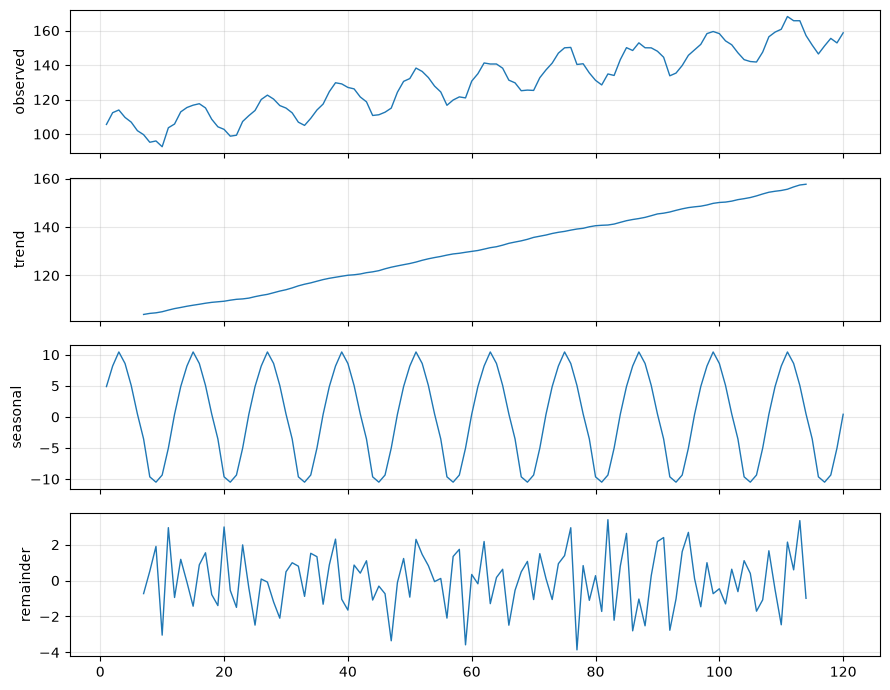

In [2]:
dec = seasonal_decompose(y, model="additive", period=12)
ok = ~np.isnan(dec.trend)
slope = np.polyfit(t[ok], dec.trend[ok], 1)[0]
print("estimated trend slope:", round(slope, 3), " (true 0.5)")
seas_est = dec.seasonal[:12]
seas_true = seasonal(np.arange(1, 13)) - seasonal(np.arange(1, 13)).mean()
print("max |seasonal est - true| over one cycle:", round(np.abs(seas_est - seas_true).max(), 2))
print("seasonal amplitude (max):", round(seas_est.max(), 2), " (true 10)")
print("remainder std:", round(np.nanstd(dec.resid), 2), " (noise sd 2)")

fig, ax = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
for a, (name, comp) in zip(ax, (("observed", dec.observed), ("trend", dec.trend),
                                 ("seasonal", dec.seasonal), ("remainder", dec.resid))):
    a.plot(t, comp, lw=1); a.set_ylabel(name); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The estimated slope and seasonal amplitude are close to the truth, and the remainder behaves like noise with standard deviation near $2$. Different smoothers would split the variation slightly differently, which is why decomposition is not a unique physical partition.

## 3. Monthly sales: moving average and exponential smoothing

The note's 12-month sales table has a trailing 3-month moving average $\tilde y_t=\frac13\sum_{j=0}^{2}y_{t-j}$ of $110, 120, 127, 140, 150, 163, 170, 180, 187, 200$ (months 3 to 12, rounded). Simple exponential smoothing updates $\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1}$.

trailing MA(3), months 3-12: [110.  120.  126.7 140.  150.  163.3 170.  180.  186.7 200. ]
rounded                    : [110 120 127 140 150 163 170 180 187 200]
alpha=0.3: one-step SSE= 8580.3   next-month forecast = 186.8
alpha=0.8: one-step SSE= 2545.7   next-month forecast = 207.4


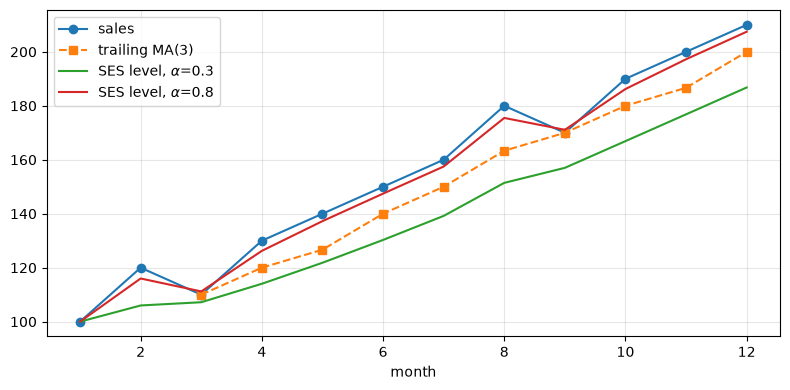

In [3]:
sales = np.array([100, 120, 110, 130, 140, 150, 160, 180, 170, 190, 200, 210], float)
months = np.arange(1, 13)

ma3 = np.full(12, np.nan)
for i in range(2, 12):
    ma3[i] = sales[i - 2:i + 1].mean()
print("trailing MA(3), months 3-12:", np.round(ma3[2:], 1))
print("rounded                    :", np.round(ma3[2:]).astype(int))

def ses(y, alpha):
    level = np.empty(len(y)); level[0] = y[0]
    for i in range(1, len(y)):
        level[i] = alpha * y[i] + (1 - alpha) * level[i - 1]
    return level

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(months, sales, "o-", label="sales")
ax.plot(months, ma3, "s--", label="trailing MA(3)")
for alpha in (0.3, 0.8):
    lvl = ses(sales, alpha)
    ax.plot(months, lvl, label=fr"SES level, $\alpha$={alpha}")
    # one-step-ahead forecast of y_t is the level at t-1
    sse = np.sum((sales[1:] - lvl[:-1]) ** 2)
    print(f"alpha={alpha}: one-step SSE={sse:7.1f}   next-month forecast = {lvl[-1]:.1f}")
ax.legend(); ax.grid(alpha=0.3); ax.set_xlabel("month"); plt.tight_layout(); plt.show()

The moving-average values reproduce the table. Both smoothers confirm the upward movement, but SES has no trend component, so its level lags behind a rising series; its forecast (the last level) sits below the latest sales of $210$. With only twelve points, any forecast is highly uncertain and should be compared with a simple baseline.

## 4. Differencing: removing trend and seasonality

The backshift operator gives $\Delta y_t=(1-B)y_t$ and $\Delta_{12}y_t=(1-B^{12})y_t$. For the simulated series, $\Delta_{12}y_t=6+\varepsilon_t-\varepsilon_{t-12}$ (the seasonal term cancels, and $12\cdot0.5=6$), whose noise variance is $2\sigma^2=8$.

first difference:   mean=0.45  var=21.26
seasonal diff (12): mean=6.01  var=7.86   (theory 6 and 8)


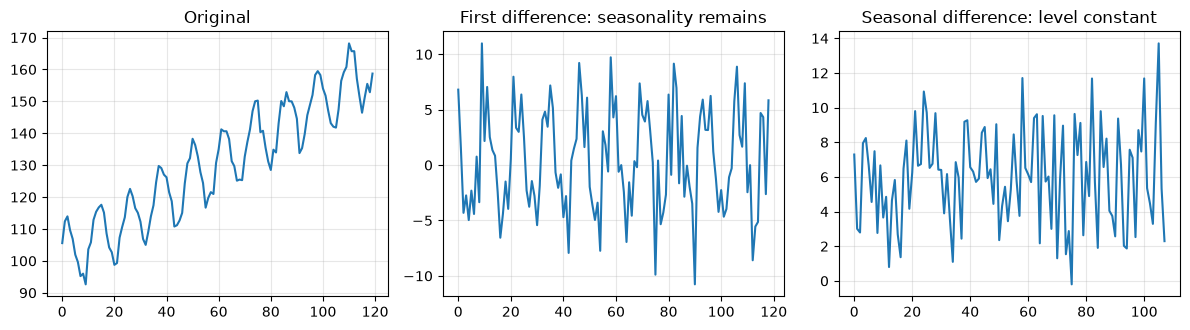

ACF of first difference at lags 6 and 12: [-0.6   0.55]


In [4]:
d1 = np.diff(y)
d12 = y[12:] - y[:-12]
print("first difference:   mean=%.2f  var=%.2f" % (d1.mean(), d1.var()))
print("seasonal diff (12): mean=%.2f  var=%.2f   (theory 6 and 8)" % (d12.mean(), d12.var()))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(y); ax[0].set_title("Original")
ax[1].plot(d1); ax[1].set_title("First difference: seasonality remains")
ax[2].plot(d12); ax[2].set_title("Seasonal difference: level constant")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("ACF of first difference at lags 6 and 12:", np.round(acf(d1, nlags=12)[[6, 12]], 2))

Seasonal differencing leaves a roughly constant mean of $6$ with variance about $8$, as the algebra predicts. First differencing removes the trend but leaves the 12-month cycle, visible as a large autocorrelation at lag 12 (and strong negative at lag 6).

## 5. Multiplicative seasonality, logs, and aliasing

If $y_t=T_tS_tR_t$ then $\log y_t=\log T_t+\log S_t+\log R_t$ and the seasonal swings become constant in the log scale. Separately, sampling fixes the Nyquist frequency at $0.5$ cycles per observation: a sinusoid of frequency $0.9$ is indistinguishable from one at $0.1$.

yearly swing, raw scale: [ 27.  92. 422.] (grows)
yearly swing, log scale: [0.5  0.51 0.54] (roughly constant)
max |cos(0.9 n) - cos(0.1 n)| on integer grid: 0.0


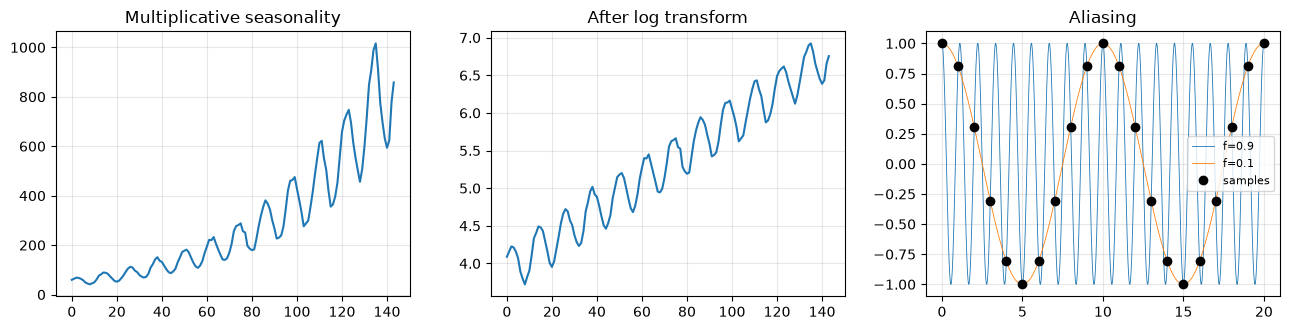

In [5]:
tt = np.arange(1, 145)
level = 50 * np.exp(0.02 * tt)
mult = level * (1 + 0.3 * np.sin(2 * np.pi * tt / 12)) * np.exp(rng.normal(0, 0.03, tt.size))
logm = np.log(mult)

def swing(v):  # amplitude of seasonal swing per year (max-min)
    return np.array([v[i:i + 12].max() - v[i:i + 12].min() for i in range(0, 144, 12)])
print("yearly swing, raw scale:", np.round(swing(mult), 0)[[0, 5, 11]], "(grows)")
print("yearly swing, log scale:", np.round(swing(logm), 2)[[0, 5, 11]], "(roughly constant)")

# aliasing: frequency 0.9 vs 0.1 cycles per observation
n = np.arange(60)
s_hi = np.cos(2 * np.pi * 0.9 * n)
s_lo = np.cos(2 * np.pi * 0.1 * n)
print("max |cos(0.9 n) - cos(0.1 n)| on integer grid:", np.abs(s_hi - s_lo).max().round(12))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(mult); ax[0].set_title("Multiplicative seasonality")
ax[1].plot(logm); ax[1].set_title("After log transform")
fine = np.linspace(0, 20, 2000)
ax[2].plot(fine, np.cos(2 * np.pi * 0.9 * fine), lw=0.6, label="f=0.9")
ax[2].plot(fine, np.cos(2 * np.pi * 0.1 * fine), lw=0.6, label="f=0.1")
ax[2].plot(n[:21], s_hi[:21], "ko", label="samples")
ax[2].set_title("Aliasing"); ax[2].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In the raw scale the seasonal swing grows with the level; after the log it is stable, which is the reason to take logs before modeling. The two sinusoids coincide at every integer sample time, so a frequency above Nyquist is misread as a lower one.

## 6. The information set: trailing versus centered smoothing

A centered moving average uses future observations, so it is retrospective. Using it as a one-step forecast input looks excellent but is leakage. We compare one-step forecasts of $y_{t}$ from a trailing average of past values with a centered average that illegally includes $y_t$ and later values.

In [6]:
rng2 = np.random.default_rng(5)
n = 500
z = np.cumsum(rng2.normal(0, 1, n))         # random walk level

w = 5
valid, leaky = [], []
idx = range(w, n - w)
for i in idx:
    valid.append(z[i - w:i].mean())                 # uses y_{i-w..i-1}: available at forecast time
    leaky.append(z[i - w // 2:i + w // 2 + 1].mean())   # centered window includes y_i itself and y_{i+1}, y_{i+2}
actual = z[w:n - w]
rmse = lambda f: np.sqrt(np.mean((actual - np.array(f)) ** 2))
naive = z[w - 1:n - w - 1]
print(f"RMSE trailing MA (valid)       : {rmse(valid):.3f}")
print(f"RMSE naive last value (valid)  : {rmse(naive):.3f}")
print(f"RMSE centered MA (uses future) : {rmse(leaky):.3f}   <-- not achievable in real time")

RMSE trailing MA (valid)       : 1.466
RMSE naive last value (valid)  : 0.961
RMSE centered MA (uses future) : 0.616   <-- not achievable in real time


The centered average appears best only because it sees the future. The valid forecasts (trailing average, last value) cannot do that; for a random walk the naive last value is the benchmark. Every transformation, scaling, and tuning step in a backtest must be recomputed using only information available at the forecast origin.

**Takeaways.** Decompose into trend, season, and remainder with a stated period; difference or log-transform for a stated reason; understand that sampling limits identifiable frequencies; and keep chronological information sets honest.